# 03b — Grid Search Around the Final Model

The random search in `03_modelling.ipynb` explored 8 hyperparameters broadly. This notebook adds a **grid
search**: a systematic check of every combination of the two hyperparameters that matter most for this model,
holding the rest at the final model's values.

- **`reg_lambda`** (L2 regularisation): the strongest effect in the random search.
- **`num_leaves`** (how complex each tree can be).

Same method as the random search: 3-fold cross-validation grouped by lot, **training set only**, scored by
macro-F1 (and defect recall). The test set is not touched.

**Decision rule (set before running):** keep the current final model unless a grid setting beats it by more than
the fold-to-fold spread of the random search (±0.007 macro-F1); if one does, re-check it on 5 folds before
switching.

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURE_NAMES

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
RANDOM_STATE = 42
SPREAD = 0.007   # fold-to-fold std of the top random-search configurations

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

feats = pd.read_parquet(ROOT / "data" / "features.parquet")
train = feats[feats["split"] == "train"].reset_index(drop=True)
X, y, groups = train[FEATURE_NAMES], train["failureType"], train["lotName"]

final = joblib.load(ROOT / "models" / "lgbm_tuned.joblib")["best_params"]
print("Final model settings:", final)

Final model settings: {'n_estimators': 676, 'learning_rate': 0.06623659776144764, 'num_leaves': 77, 'min_child_samples': 8, 'subsample': 0.7799016533479063, 'colsample_bytree': 0.5870266456536466, 'reg_lambda': 2.339586455122247, 'class_weight': 'balanced'}


## The grid: 3 × 3 = 9 combinations, centred on the final model's values

In [2]:
grid = {
    "reg_lambda": sorted({0.5, round(final["reg_lambda"], 2), 8.0}),
    "num_leaves": sorted({31, final["num_leaves"], 127}),
}
fixed = {k: v for k, v in final.items() if k not in grid}
print("Grid:", grid)
print("Fixed:", fixed)

def defect_recall(y_true, y_pred):
    return recall_score(np.asarray(y_true) != "none", np.asarray(y_pred) != "none")

GRID_CSV = ROOT / "reports" / "grid_search_results.csv"
if GRID_CSV.exists():
    res = pd.read_csv(GRID_CSV)
    print(f"Loaded cached grid results from {GRID_CSV.name}")
else:
    search = GridSearchCV(
        LGBMClassifier(**fixed, subsample_freq=1, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE),
        grid,
        scoring={"macro_f1": "f1_macro", "defect_recall": make_scorer(defect_recall)},
        refit=False,
        cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=1,
    )
    t0 = time.time()
    search.fit(X, y, groups=groups)
    print(f"Grid search took {(time.time() - t0) / 60:.1f} min")
    res = pd.DataFrame(search.cv_results_).rename(columns=lambda c: c.replace("param_", ""))
    res = res[["reg_lambda", "num_leaves", "mean_test_macro_f1", "std_test_macro_f1",
               "mean_test_defect_recall", "mean_fit_time"]]
    res.to_csv(GRID_CSV, index=False)

res.sort_values("mean_test_macro_f1", ascending=False).round(4)

Grid: {'reg_lambda': [0.5, 2.34, 8.0], 'num_leaves': [31, 77, 127]}
Fixed: {'n_estimators': 676, 'learning_rate': 0.06623659776144764, 'min_child_samples': 8, 'subsample': 0.7799016533479063, 'colsample_bytree': 0.5870266456536466, 'class_weight': 'balanced'}
Loaded cached grid results from grid_search_results.csv


,reg_lambda,num_leaves,mean_test_macro_f1,std_test_macro_f1,mean_test_defect_recall,mean_fit_time
3,0.50,77,0.8962,0.0051,0.9477,26.6631
0,0.50,31,0.8956,0.0066,0.9522,18.5190
6,0.50,127,0.8932,0.0054,0.9452,30.6021
4,2.34,77,0.8929,0.0059,0.9505,26.1596
7,2.34,127,0.8922,0.0063,0.9486,38.5980
1,2.34,31,0.8916,0.0065,0.9550,18.6346
5,8.00,77,0.8913,0.0048,0.9531,37.2074
8,8.00,127,0.8904,0.0058,0.9522,55.5766
2,8.00,31,0.8896,0.0050,0.9600,18.5038


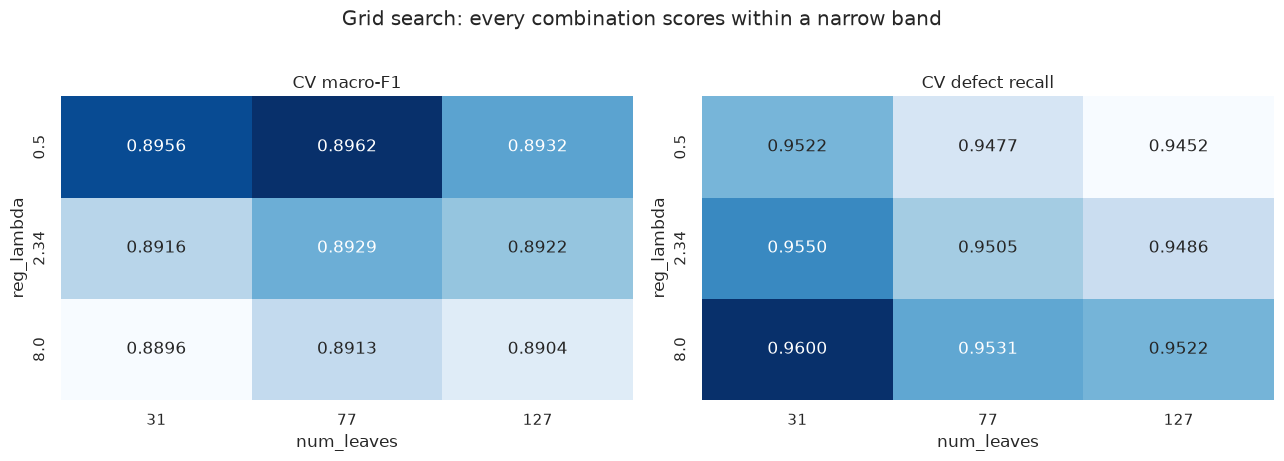

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in zip(axes, ["mean_test_macro_f1", "mean_test_defect_recall"],
                          ["CV macro-F1", "CV defect recall"]):
    table = res.pivot(index="reg_lambda", columns="num_leaves", values=col)
    sns.heatmap(table, annot=True, fmt=".4f", cmap="Blues", ax=ax, cbar=False)
    ax.set(title=title, xlabel="num_leaves", ylabel="reg_lambda")
fig.suptitle("Grid search: every combination scores within a narrow band", y=1.02)
plt.tight_layout(); savefig("grid_search_heatmap"); plt.show()

## Does any grid setting beat the final model?

In [4]:
is_final = (res["reg_lambda"].round(2) == round(final["reg_lambda"], 2)) & (res["num_leaves"] == final["num_leaves"])
current = res.loc[is_final].iloc[0]
best = res.sort_values("mean_test_macro_f1", ascending=False).iloc[0]
gain = best["mean_test_macro_f1"] - current["mean_test_macro_f1"]
spread_all = res["mean_test_macro_f1"].max() - res["mean_test_macro_f1"].min()

print(f"Final model's setting in this grid (reg_lambda rounded to {round(final['reg_lambda'], 2)}): macro-F1 {current['mean_test_macro_f1']:.4f}, "
      f"defect recall {current['mean_test_defect_recall']:.4f}")
print(f"Best grid setting (reg_lambda={best['reg_lambda']}, num_leaves={int(best['num_leaves'])}): "
      f"macro-F1 {best['mean_test_macro_f1']:.4f}, defect recall {best['mean_test_defect_recall']:.4f}")
print(f"Gain over final: {gain:+.4f} (threshold {SPREAD}) | range across all 9 settings: {spread_all:.4f}")
print("→ Keep the current final model." if gain <= SPREAD else "→ Re-check the best grid setting on 5 folds.")

Final model's setting in this grid (reg_lambda rounded to 2.34): macro-F1 0.8929, defect recall 0.9505
Best grid setting (reg_lambda=0.5, num_leaves=77): macro-F1 0.8962, defect recall 0.9477
Gain over final: +0.0033 (threshold 0.007) | range across all 9 settings: 0.0066
→ Keep the current final model.


## Summary

- **Keep the current final model.** The best grid setting (`reg_lambda` 0.5, `num_leaves` 77) scores +0.0033
  macro-F1 over it, below the ±0.007 fold-to-fold spread, so the difference is noise.
- **The landscape is flat:** all 9 settings fall within 0.0066 macro-F1 (0.8896–0.8962), confirming the random
  search's finding.
- **The two heatmaps mirror each other:** stronger regularisation and simpler trees (`reg_lambda` 8, 31 leaves)
  catch the most defects (96.0% defect recall) but have the lowest macro-F1 (0.8896). It is the same
  precision-vs-recall trade-off seen with class weighting — a lever the fab could use if catching every defect
  matters more than balanced accuracy.
- **Method note:** grid search tested 9 combinations of 2 hyperparameters exhaustively; the random search
  covered 8 hyperparameters with 25 samples. Together: broad exploration first, then a systematic check of
  the two that matter most.
